In [24]:
from audioop import rms
from time import process_time_ns
from tkinter import E
import numpy as np
import scipy.optimize.optimize
from matplotlib import pyplot as plt
from scipy.interpolate import interpn
from scipy.interpolate import griddata
import scipy.io as sio
import math
from monolithic.math.statistics import rmse, vrr,pv
from monolithic.plot import show_surface_map
from scipy import *
from scipy import signal
from monolithic.math import remove_surface, remove_sphere, remove_polynomials
import copy
from mpl_toolkits.mplot3d import Axes3D

In [25]:
g = 0.1   #阻尼因子,值≤1时，g值越大收敛速度越快，而g值过大则迭代发散
s = 0.95  #s是g的修正系数,s的值最好是接近1的值

In [26]:
surfFile = 'E:\\Codes\Multi-Tool\\1-initial-map\\data\\initial_map_rectangular_pap_60mm.mat'
readData = sio.loadmat(surfFile) # 读出readData的内容
X = readData['X']
Y = readData['Y']
Z = readData['Z']

dx = np.median(np.diff(X[0, :]))

print("Lateral resolution = ", dx, " m")


Lateral resolution =  0.00022222167172003537  m


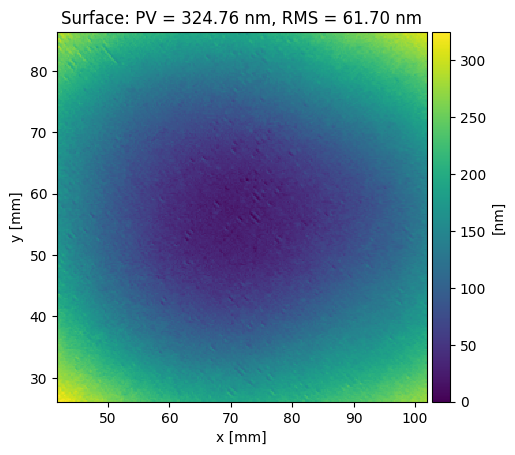

In [27]:
show_surface_map(X, Y, Z)
plt.show()

In [28]:
def tif_surpergaussian_2d(
    x2d: np.ndarray,
    y2d: np.ndarray,
    t: float,
    a: float,
    sigma1d: np.ndarray,
    mu1d: np.ndarray = np.array([0, 0]),
    p: float = 1.0
) -> np.ndarray:
    '''
    Returns a 2D super Gaussian function
    Parameters
    ----------
        x2d: `numpy.ndarray`
            x coordinates [m] 
        y2d: `numpy.ndarray`
            y coordinates [m]
        t: `float`
            dwell time [m]
        a: `float`
            PRR [m/s]
        sigma1d: `numpy.ndarray`
            variances in x and y [m]
        mu1d: `numpy.ndarray`
            mu[2] = center x and y
        p: `numpy.ndarray`
            power
    
    Returns
    -------
        `numpy.ndarray`
        2D Super Gaussian profile
    '''
    return t * a * np.exp(-((x2d - mu1d[0])**2 / (2 * sigma1d[0]**2) + (y2d - mu1d[1])**2 / (2 * sigma1d[1]**2))**p)

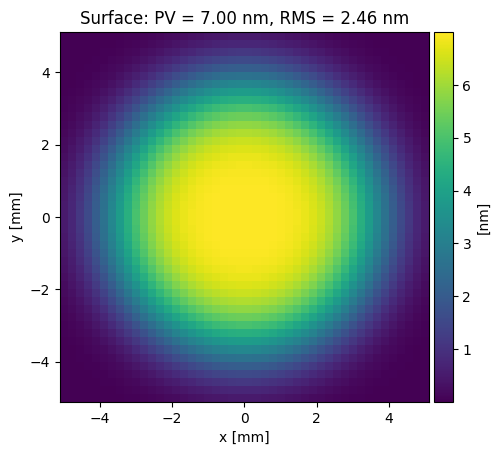

In [34]:
Xtif, Ytif = np.meshgrid(np.linspace(-5e-3, 5e-3, int(10e-3 / dx) + 1),
                    np.linspace(-5e-3, 5e-3, int(10e-3 / dx + 1)))
Ytif = -Ytif
R = tif_surpergaussian_2d(
    Xtif, Ytif,
    1,
    7e-9,
    [2.77e-3, 2.77e-3],
    [0, 0],
    2
)
show_surface_map(Xtif, Ytif, R)
plt.show()

TypeError: Dimensions of C (271, 271) are incompatible with X (46) and/or Y (46); see help(pcolormesh)

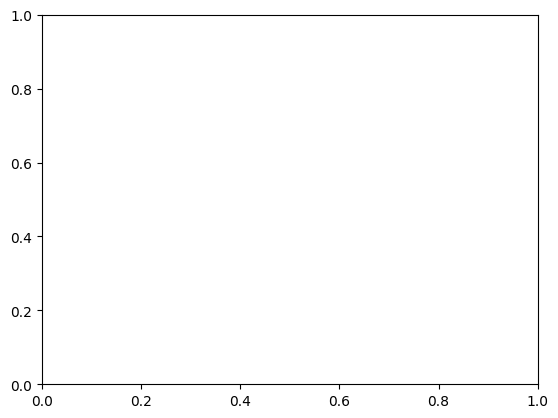

In [32]:
R.shape

(271, 271)

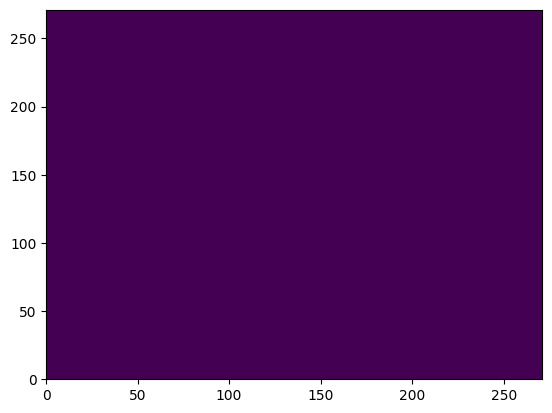

In [ ]:
readData

{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Sun Dec 05 16:16:10 2021',
 '__version__': '1.0',
 '__globals__': [],
 'X': array([[0.04177767, 0.0419999 , 0.04222212, ..., 0.10133308, 0.1015553 ,
         0.10177753],
        [0.04177767, 0.0419999 , 0.04222212, ..., 0.10133308, 0.1015553 ,
         0.10177753],
        [0.04177767, 0.0419999 , 0.04222212, ..., 0.10133308, 0.1015553 ,
         0.10177753],
        ...,
        [0.04177767, 0.0419999 , 0.04222212, ..., 0.10133308, 0.1015553 ,
         0.10177753],
        [0.04177767, 0.0419999 , 0.04222212, ..., 0.10133308, 0.1015553 ,
         0.10177753],
        [0.04177767, 0.0419999 , 0.04222212, ..., 0.10133308, 0.1015553 ,
         0.10177753]]),
 'Y': array([[0.08622201, 0.08622201, 0.08622201, ..., 0.08622201, 0.08622201,
         0.08622201],
        [0.08599979, 0.08599979, 0.08599979, ..., 0.08599979, 0.08599979,
         0.08599979],
        [0.08577757, 0.08577757, 0.08577757, ..., 0.08577757, 0.0857